# 003 · 退相干与主方程

跟做官方qubit-dynamics，原文在third_party/qutip_tutorials/003_qubit-dynamics.md。本笔记补充精确阻尼解与密度矩阵检查。H=δσx/2，C=sqrt(g)σz。

In [1]:
from pathlib import Path
import sys
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if not (root / 'code').is_dir():
    root = root.parent
if not (root / 'code').is_dir():
    raise RuntimeError('请在项目根目录或notebooks目录运行')
sys.path.insert(0, str(root / 'code'))
print('当前解释器：', sys.executable)
options = dict(atol=1e-11, rtol=1e-9, method='dop853', store_states=True, normalize_output=False)


当前解释器： D:\Master.s-work\Software-needed-for-master.s-work\python\main\python.exe


## 精确解与近似解
z满足z″+2g z′+δ²z=0，初始z=1、z′=0。下面计算欠阻尼解；教程的简单余弦作为近似显示。

精确解最大误差: 1.5265566588595902e-15
原文近似最大误差: 0.03857617847537986
迹误差: 8.881784197001252e-16
最小本征值: 0.0


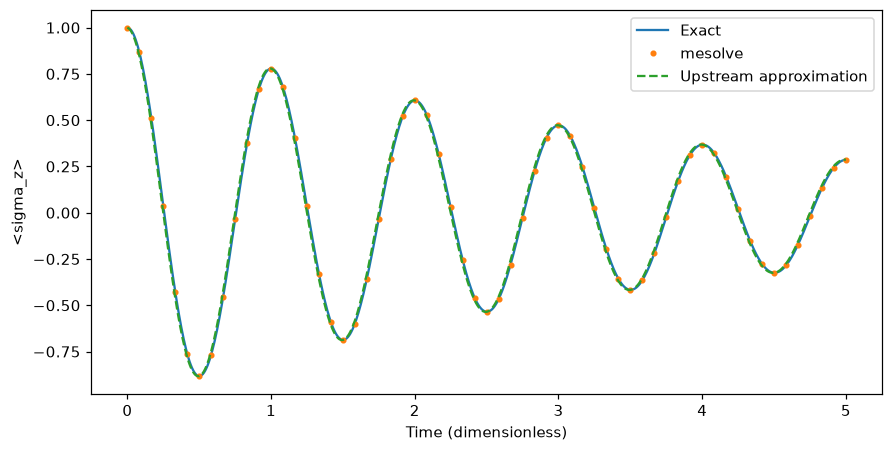

In [2]:
delta=2*np.pi;g=0.25;times=np.linspace(0,5,601)
psi=qt.basis(2,0);H=delta*qt.sigmax()/2
result=qt.mesolve(H,psi.proj(),times,[np.sqrt(g)*qt.sigmaz()],e_ops=[qt.sigmaz()],options=options)
nu=np.sqrt(delta**2-g**2)
exact=np.exp(-g*times)*(np.cos(nu*times)+g/nu*np.sin(nu*times))
approx=np.exp(-g*times)*np.cos(delta*times)
z=np.asarray(result.expect[0])
np.testing.assert_allclose(z,exact,atol=1e-7,rtol=0)
print('精确解最大误差:',np.max(abs(z-exact)))
print('原文近似最大误差:',np.max(abs(z-approx)))
print('迹误差:',max(abs(rho.tr()-1) for rho in result.states))
print('最小本征值:',min(min(rho.eigenenergies()) for rho in result.states))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
ax.plot(times,exact,label='Exact')
ax.plot(times[::10],z[::10],'o',ms=3,label='mesolve')
ax.plot(times,approx,'--',label='Upstream approximation')
ax.set(xlabel='Time (dimensionless)',ylabel='<sigma_z>');ax.legend()
display(fig);plt.close(fig)


## 三种Bloch轨迹
先设倾斜场；无耗散保持纯态，退相干和弛豫使轨迹发生不同变化。这里sigmam沿用官方约定，把第0基矢送到第1基矢。

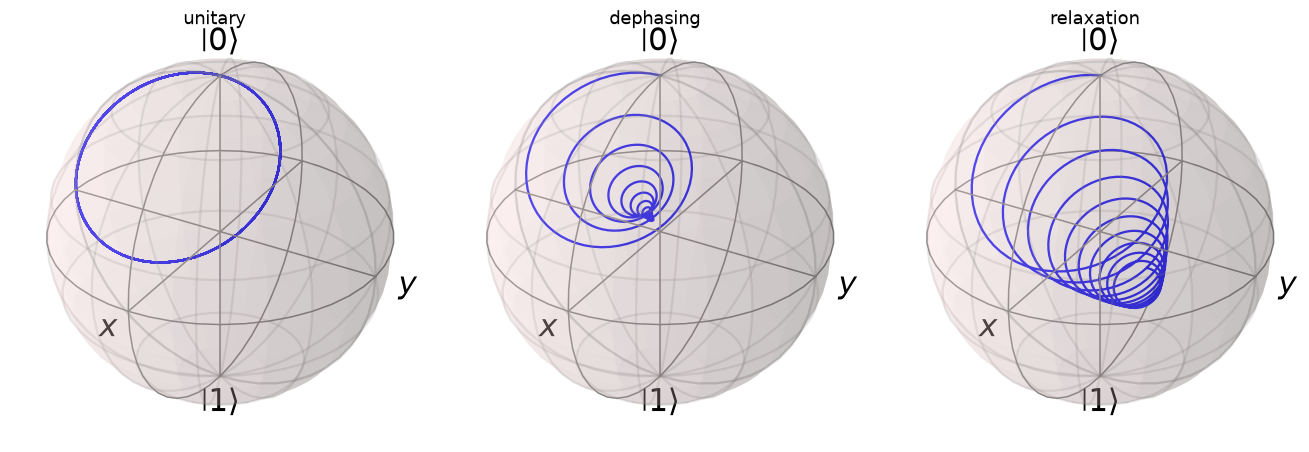

In [3]:
theta=0.2*np.pi
H_tilt=delta*(np.cos(theta)*qt.sigmaz()+np.sin(theta)*qt.sigmax())
fig=plt.figure(figsize=(12,4),layout='constrained')
for index,(name,cops) in enumerate([('unitary',[]),('dephasing',[np.sqrt(0.5)*qt.sigmaz()]),('relaxation',[np.sqrt(0.5)*qt.sigmam()])],1):
    evolution=qt.mesolve(H_tilt,psi.proj(),times,cops,e_ops=[qt.sigmax(),qt.sigmay(),qt.sigmaz()],options=options)
    xyz=np.asarray(evolution.expect)
    for rho in evolution.states:
        np.testing.assert_allclose(rho.tr(),1,atol=1e-7)
        np.testing.assert_allclose(rho.full(),rho.full().conj().T,atol=1e-10)
        if min(rho.eigenenergies()) < -1e-7:raise RuntimeError('密度矩阵正性失败')
    ax=fig.add_subplot(1,3,index,projection='3d')
    sphere=qt.Bloch(fig=fig,axes=ax);sphere.add_points(xyz,meth='l');sphere.render();ax.set_title(name)
display(fig);plt.close(fig)


## 独立核验衰减方向与因子2
显式选g=|0⟩、e=|1⟩，直接用|g⟩⟨e|写collapse operator。

In [4]:
ground=qt.basis(2,0);excited=qt.basis(2,1);gamma=0.7
decay=qt.mesolve(0*qt.sigmaz(),excited.proj(),times,[np.sqrt(gamma)*ground*excited.dag()],e_ops=[excited.proj()],options=options)
np.testing.assert_allclose(decay.expect[0],np.exp(-gamma*times),atol=1e-7,rtol=0)
plus=(ground+excited).unit();gamma_phi=0.4
coherence=qt.mesolve(0*qt.sigmaz(),plus.proj(),times,[np.sqrt(gamma_phi/2)*qt.sigmaz()],e_ops=[qt.sigmax()],options=options)
np.testing.assert_allclose(coherence.expect[0],np.exp(-gamma_phi*times),atol=1e-7,rtol=0)
print('T1和T2解析基准通过')


T1和T2解析基准通过


## 自己改一处
把退相干算符从sqrt(gamma_phi/2)σz改成sqrt(gamma_phi)σz，预测衰减快多少，再改解析式验证。想增加g到大于delta时，改用讲义中的过阻尼公式。